In [2]:


import kagglehub
from pathlib import Path
from collections import Counter

path = kagglehub.dataset_download(
    "ahamedfarouk/cew-dataset"
)

DATA_DIR = Path(path)

files = [p for p in DATA_DIR.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("File types:", Counter(p.suffix.lower() for p in files))

for p in files[:15]:
    print(p.relative_to(DATA_DIR))


/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Total files: 27200
File types: Counter({'.jpg': 27200})
CEW/closed/aug_14_closed_eye_1552.BMP_face_1.jpg
CEW/closed/aug_0_closed_eye_0863.jpg_face_1.jpg
CEW/closed/aug_0_closed_eye_2692.jpg_face_1.jpg
CEW/closed/aug_0_closed_eye_2687.jpg_face_1.jpg
CEW/closed/aug_10_closed_eye_0687.jpg_face_1.jpg
CEW/closed/aug_9_closed_eye_1548.BMP_face_1.jpg
CEW/closed/aug_14_closed_eye_0653.jpg_face_2.jpg
CEW/closed/aug_12_closed_eye_1922.jpg_face_2.jpg
CEW/closed/aug_12_closed_eye_1937.jpg_face_2.jpg
CEW/closed/closed_eye_1350.jpg_face_2.jpg
CEW/closed/aug_8_closed_eye_2168.jpg_face_1.jpg
CEW/closed/aug_12_closed_eye_1087.jpg_face_2.jpg
CEW/closed/aug_12_closed_eye_1647.jpg_face_1.jpg
CEW/closed/aug_1_closed_eye_0766.jpg_face_1.jpg
CEW/closed/aug_12_closed_eye_1652.jpg_face_1.jpg


In [3]:

from pathlib import Path
from collections import Counter

DATA_DIR = Path(path)

# Find all images
image_paths = [
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
]

print("Total images:", len(image_paths))

print("\nFile extensions:")
print(Counter(p.suffix.lower() for p in image_paths))

print("\nFirst 20 image paths:")
for p in image_paths[:20]:
    print(p.relative_to(DATA_DIR))

print("\nParent folders:")
print(Counter(p.parent.name for p in image_paths))


Total images: 27200

File extensions:
Counter({'.jpg': 27200})

First 20 image paths:
CEW/closed/aug_14_closed_eye_1552.BMP_face_1.jpg
CEW/closed/aug_0_closed_eye_0863.jpg_face_1.jpg
CEW/closed/aug_0_closed_eye_2692.jpg_face_1.jpg
CEW/closed/aug_0_closed_eye_2687.jpg_face_1.jpg
CEW/closed/aug_10_closed_eye_0687.jpg_face_1.jpg
CEW/closed/aug_9_closed_eye_1548.BMP_face_1.jpg
CEW/closed/aug_14_closed_eye_0653.jpg_face_2.jpg
CEW/closed/aug_12_closed_eye_1922.jpg_face_2.jpg
CEW/closed/aug_12_closed_eye_1937.jpg_face_2.jpg
CEW/closed/closed_eye_1350.jpg_face_2.jpg
CEW/closed/aug_8_closed_eye_2168.jpg_face_1.jpg
CEW/closed/aug_12_closed_eye_1087.jpg_face_2.jpg
CEW/closed/aug_12_closed_eye_1647.jpg_face_1.jpg
CEW/closed/aug_1_closed_eye_0766.jpg_face_1.jpg
CEW/closed/aug_12_closed_eye_1652.jpg_face_1.jpg
CEW/closed/aug_8_closed_eye_1490.jpg_face_1.jpg
CEW/closed/aug_14_closed_eye_0923.jpg_face_1.jpg
CEW/closed/aug_4_closed_eye_1736.jpg_face_1.jpg
CEW/closed/aug_2_closed_eye_0847.jpg_face_1.jpg

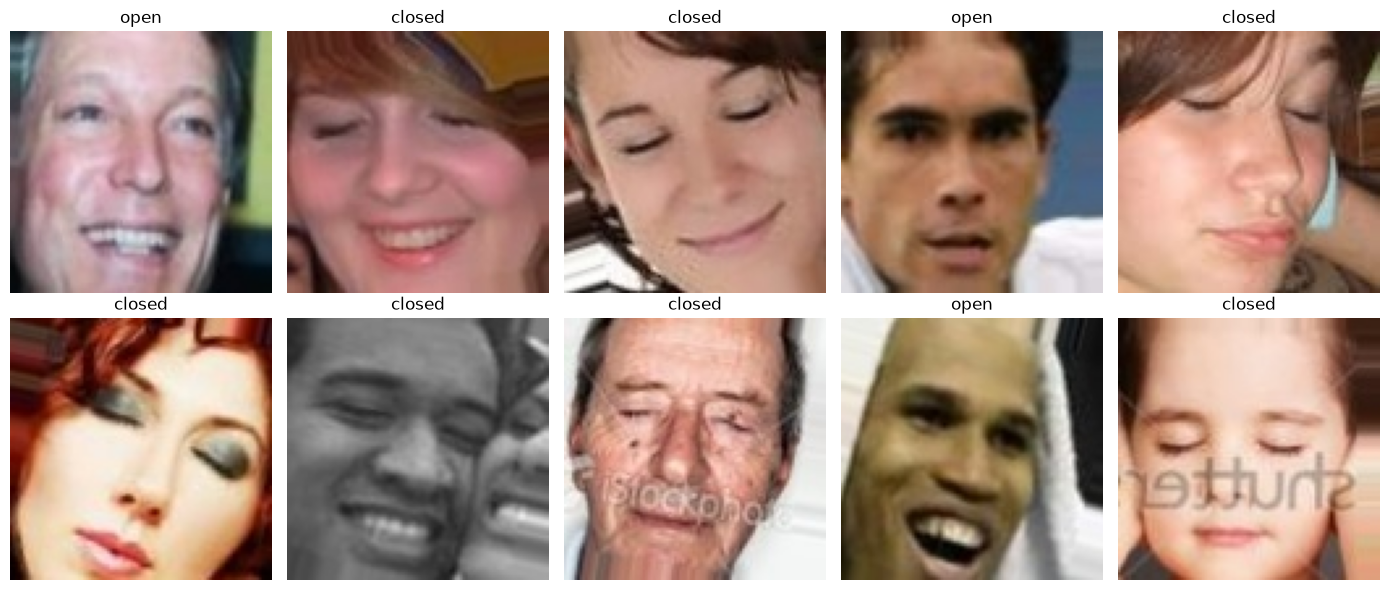

In [4]:

import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

samples = random.sample(
    image_paths,
    min(10, len(image_paths))
)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for ax in axes.flat:
    ax.axis("off")

for ax, image_path in zip(axes.flat, samples):
    img = Image.open(image_path)

    ax.imshow(img)
    ax.set_title(image_path.parent.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:

from collections import Counter

print("Images per folder:")

folder_counts = Counter(
    p.parent.name for p in image_paths
)

for folder, count in folder_counts.items():
    print(f"{folder}: {count}")


Images per folder:
closed: 12864
open: 14336


In [6]:

import pandas as pd
import re

records = []

for image_path in image_paths:
    label_name = image_path.parent.name.lower()

    if label_name not in ["open", "closed"]:
        continue

    # Remove augmentation prefix
    original_name = re.sub(
        r"^aug_\d+_",
        "",
        image_path.name
    )

    # Remove face crop suffix
    original_name = re.sub(
        r"_face_\d+\.jpg$",
        "",
        original_name,
        flags=re.IGNORECASE
    )

    records.append({
        "image_path": str(image_path),
        "label": 1 if label_name == "open" else 0,
        "source_id": original_name,
        "augmented": image_path.name.startswith("aug_")
    })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("Original images:",
      (~df["augmented"]).sum())
print("Augmented images:",
      df["augmented"].sum())
print("Unique source groups:",
      df["source_id"].nunique())

display(df.head())


Total images: 27200
Original images: 1700
Augmented images: 25500
Unique source groups: 1656


,image_path,label,source_id,augmented
0,/Users/kaykay/.cache/kagglehub/datasets/ahamed...,0,closed_eye_1552.BMP,True
1,/Users/kaykay/.cache/kagglehub/datasets/ahamed...,0,closed_eye_0863.jpg,True
2,/Users/kaykay/.cache/kagglehub/datasets/ahamed...,0,closed_eye_2692.jpg,True
3,/Users/kaykay/.cache/kagglehub/datasets/ahamed...,0,closed_eye_2687.jpg,True
4,/Users/kaykay/.cache/kagglehub/datasets/ahamed...,0,closed_eye_0687.jpg,True


In [7]:

from sklearn.model_selection import GroupShuffleSplit

splitter1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=42
)

train_idx, temp_idx = next(
    splitter1.split(
        df,
        groups=df["source_id"]
    )
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

splitter2 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    splitter2.split(
        temp_df,
        groups=temp_df["source_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


Training: 19024
Validation: 4112
Testing: 4064


In [8]:

train_sources = set(train_df["source_id"])
val_sources = set(val_df["source_id"])
test_sources = set(test_df["source_id"])

assert train_sources.isdisjoint(val_sources)
assert train_sources.isdisjoint(test_sources)
assert val_sources.isdisjoint(test_sources)

assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("No source-image overlap detected!")

for name, subset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}")
    print("Images:", len(subset))
    print("Unique source images:",
          subset["source_id"].nunique())

    print("Class distribution:")
    print(
        subset["label"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )


No source-image overlap detected!

Training
Images: 19024
Unique source images: 1159
Class distribution:
label
0    46.93
1    53.07
Name: proportion, dtype: float64

Validation
Images: 4112
Unique source images: 248
Class distribution:
label
0    49.03
1    50.97
Name: proportion, dtype: float64

Testing
Images: 4064
Unique source images: 249
Class distribution:
label
0    47.24
1    52.76
Name: proportion, dtype: float64


In [9]:

# Original images for validation and testing
val_original = val_df[
    ~val_df["augmented"]
].copy()

test_original = test_df[
    ~test_df["augmented"]
].copy()

print("Training images:", len(train_df))
print("Validation originals:", len(val_original))
print("Testing originals:", len(test_original))

print("\nValidation class counts:")
print(val_original["label"].value_counts())

print("\nTest class counts:")
print(test_original["label"].value_counts())

# Confirm both classes are represented
assert val_original["label"].nunique() == 2
assert test_original["label"].nunique() == 2


Training images: 19024
Validation originals: 257
Testing originals: 254

Validation class counts:
label
1    131
0    126
Name: count, dtype: int64

Test class counts:
label
1    134
0    120
Name: count, dtype: int64


In [10]:

train_original = train_df[
    ~train_df["augmented"]
].copy()

print("Original training images:", len(train_original))
print(train_original["label"].value_counts())


Original training images: 1189
label
1    631
0    558
Name: count, dtype: int64


In [11]:

import tensorflow as tf

IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)

    # Keep pixel values in the 0–255 range.
    # MobileNetV2 preprocessing happens in the model.
    return image, tf.cast(label, tf.float32)

def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=42)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = make_dataset(train_original, training=True)
val_ds = make_dataset(val_original)
test_ds = make_dataset(test_original)


In [12]:

from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(160, 160, 3))

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomContrast(0.1)(x)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 160, 160, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 160, 160, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "best_cew_mobilenet.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)


Epoch 1/8


/opt/homebrew/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


38/38 ━━━━━━━━━━━━━━━━━━━━ 28s 625ms/step - accuracy: 0.6770 - loss: 0.6019 - val_accuracy: 0.7276 - val_loss: 0.5475
Epoch 2/8
38/38 ━━━━━━━━━━━━━━━━━━━━ 21s 549ms/step - accuracy: 0.7637 - loss: 0.5136 - val_accuracy: 0.7860 - val_loss: 0.4989
Epoch 3/8
38/38 ━━━━━━━━━━━━━━━━━━━━ 25s 652ms/step - accuracy: 0.8082 - loss: 0.4397 - val_accuracy: 0.8054 - val_loss: 0.4640
Epoch 4/8
38/38 ━━━━━━━━━━━━━━━━━━━━ 19s 500ms/step - accuracy: 0.8183 - loss: 0.4147 - val_accuracy: 0.8054 - val_loss: 0.4605
Epoch 5/8
38/38 ━━━━━━━━━━━━━━━━━━━━ 19s 496ms/step - accuracy: 0.8276 - loss: 0.3839 - val_accuracy: 0.8171 - val_loss: 0.4393
Epoch 6/8
38/38 ━━━━━━━━━━━━━━━━━━━━ 17s 463ms/step - accuracy: 0.8352 - loss: 0.3832 - val_accuracy: 0.8210 - val_loss: 0.4352
Epoch 7/8
38/38 ━━━━━━━━━━━━━━━━━━━━ 17s 448ms/step - accuracy: 0.8444 - loss: 0.3608 - val_accuracy: 0.8405 - val_loss: 0.4107
Epoch 8/8
38/38 ━━━━━━━━━━━━━━━━━━━━ 16s 426ms/step - accuracy: 0.8562 - loss: 0.3413 - val_accuracy: 0.8405 - val

8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 441ms/step
              precision    recall  f1-score   support

      Closed     0.8644    0.8500    0.8571       120
        Open     0.8676    0.8806    0.8741       134

    accuracy                         0.8661       254
   macro avg     0.8660    0.8653    0.8656       254
weighted avg     0.8661    0.8661    0.8661       254



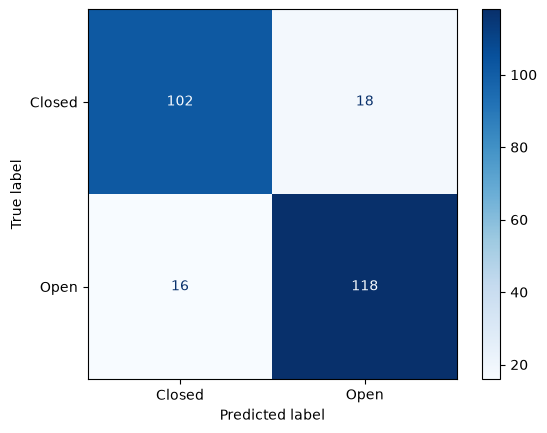

In [14]:

import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

model = tf.keras.models.load_model(
    "best_cew_mobilenet.keras"
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
]).astype(int)

y_prob = model.predict(test_ds).flatten()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_true,
    y_pred,
    target_names=["Closed", "Open"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    cm,
    display_labels=["Closed", "Open"]
).plot(cmap="Blues")

plt.show()


In [ ]:

from pathlib import Path

# Create models folder
save_dir = Path("models")
save_dir.mkdir(parents=True, exist_ok=True)

# Load the best trained model
model = tf.keras.models.load_model(
    "best_cew_mobilenet.keras"
)

# Save it inside the models folder
model.save(
    str(save_dir / "best_cew_mobilenet.keras")
)

print("Model saved successfully!")


Model saved successfully!


In [16]:
import os
print(os.getcwd())

/Users/kaykay/Documents/Personal Projects/Driver Drowsiness


In [17]:

# Convert Keras model to TensorFlow Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Optimize model size
converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]

# Perform conversion
tflite_model = converter.convert()

# Save TensorFlow Lite model
output_path = save_dir / "eye_state_model.tflite"

with open(output_path, "wb") as f:
    f.write(tflite_model)

print("TensorFlow Lite model saved!")
print("Saved at:", output_path.resolve())

print(
    "Model size (MB):",
    round(len(tflite_model) / (1024 * 1024), 2)
)


INFO:tensorflow:Assets written to: /var/folders/cc/qbhzgn5d51jf6tv9dsr0rb100000gn/T/tmp0r8upv41/assets


INFO:tensorflow:Assets written to: /var/folders/cc/qbhzgn5d51jf6tv9dsr0rb100000gn/T/tmp0r8upv41/assets


Saved artifact at '/var/folders/cc/qbhzgn5d51jf6tv9dsr0rb100000gn/T/tmp0r8upv41'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  5003549520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003554896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003554128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003554704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003555472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003552784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003555088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003555280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003553168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003555664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5003553552: TensorS

W0000 00:00:1795070041.872832 2715245 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1795070041.872856 2715245 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1795070041.873580 2715245 reader.cc:83] Reading SavedModel from: /var/folders/cc/qbhzgn5d51jf6tv9dsr0rb100000gn/T/tmp0r8upv41
I0000 00:00:1795070041.881061 2715245 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1795070041.881084 2715245 reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/cc/qbhzgn5d51jf6tv9dsr0rb100000gn/T/tmp0r8upv41
I0000 00:00:1795070041.948811 2715245 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1795070041.962429 2715245 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1795070042.419706 2715245 loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/cc/qbhzgn5d51jf6tv9dsr0rb100000gn/T/tmp0r8upv41
I0000 00:00:1795070042.540589 2715245 lo

In [ ]:

interpreter = tf.lite.Interpreter(
    model_path=str(output_path)
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input details:")
print("Shape:", input_details[0]["shape"])
print("Type:", input_details[0]["dtype"])

print("\nOutput details:")
print("Shape:", output_details[0]["shape"])
print("Type:", output_details[0]["dtype"])


Input details:
Shape: [  1 160 160   3]
Type: <class 'numpy.float32'>

Output details:
Shape: [1 1]
Type: <class 'numpy.float32'>


/opt/homebrew/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [19]:

for file in save_dir.iterdir():
    print(
        file.name,
        "-",
        round(file.stat().st_size / (1024 * 1024), 2),
        "MB"
    )


best_cew_mobilenet.keras - 9.2 MB
eye_state_model.tflite - 2.41 MB
